# <a id='toc1_'></a>[TFM. Desentrañando los misterios del cerebro femenino: WiDS Datathon 2025](#toc0_)

**Índice**<a id='toc0_'></a>    
- [TFM. Desentrañando los misterios del cerebro femenino: WiDS Datathon 2025](#toc1_)    
  - 1. [Introducción](#toc1_1_)    
  - 2. [Datos](#toc1_2_)    
  - 3. [EDA](#toc1_3_)    
    - 3.1. [Datos cuantitativos](#toc1_3_1_)    
    - 3.2. [Datos categoricos](#toc1_3_2_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=0
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
# Importar librerias
import numpy as np
import pandas as pd
import seaborn as sns

import os
import matplotlib.pyplot as plt

import sklearn
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, accuracy_score, confusion_matrix, roc_curve
from scipy.stats import zscore, pearsonr, uniform
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, StratifiedKFold, RandomizedSearchCV

from scipy.io import loadmat

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score

## 1. <a id='toc1_1_'></a>[Introducción](#toc0_)

Analizaremos datos de diagnóstico, datos sociodemográficos, emocionales y de crianza, y datos de resonancia magnética funcional de la Healthy Brain Network (HBN). 
Los datos de resonancia magnética funcional se utilizan para extraer una serie temporal de actividad por región cerebral, y las series temporales de estas regiones se correlacionan para obtener matrices de conectoma funcionales de resonancia magnética.

El objetivo es construir un modelo para predecir tanto el sexo de un individuo como su diagnóstico de TDAH utilizando datos de imágenes cerebrales funcionales de niños y adolescentes y su información sociodemográfica, emocional y de crianza.

**Pregunta**

"¿Qué patrones de actividad cerebral están asociados con el TDAH; ¿Son diferentes entre hombres y mujeres y, si es así, cómo?"

**Tarea**

Consiste en crear un modelo de resultados múltiples para predecir dos variables objetivo separadas: 1) TDAH (1 = sí o 0 = no) y 2) mujer (1 = sí o 0 = no).

**Habilidades de ciencia de datos a desarrollar**

- Limpieza y preprocesamiento de datos para el desarrollo y análisis de modelos
- Comprensión de las correlaciones
- Selección de modelos de regresión (estadísticos, aprendizaje automático)
- Ajuste/pruebas del modelo de regresión (validación cruzada, evitar sobre/subajuste, estratificación de los datos durante el entrenamiento)
- Explicación de los factores que impulsan el rendimiento del modelo
- Predicción multiresultado

## 2. <a id='toc1_2_'></a>[Datos](#toc0_)

** Descipcion de los archivos y sus columnas

In [2]:
# Archivos de TRAIN
train_cat = pd.read_excel('data/TRAIN/TRAIN_CATEGORICAL_METADATA_new.xlsx')
train_FCM = pd.read_csv('data/TRAIN/TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv')
train_quant = pd.read_excel('data/TRAIN/TRAIN_QUANTITATIVE_METADATA_new.xlsx')
train_sol = pd.read_excel('data/TRAIN/TRAINING_SOLUTIONS.xlsx')

In [3]:
# Variables categoricas de TRAIN
train_cat.head()

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ
0,00aIpNTbG5uh,2019,4,1.0,0.0,3.0,21.0,45.0,NaN,NaN
1,00fV0OyyoLfw,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0
2,04X1eiS79T4B,2017,1,1.0,2.0,2.0,9.0,0.0,NaN,NaN
3,05ocQutkURd6,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0
4,06YUNBA9ZRLq,2018,1,0.0,1.0,2.0,12.0,0.0,NaN,NaN


In [4]:
print(f"Tamaño: {train_cat.shape}")
print(f"Columnas: {train_cat.columns}")

Tamaño: (1213, 10)
Columnas: Index(['participant_id', 'Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ'],
      dtype='object')


In [5]:
# Funtional Connectome Matrices: cómo interactúan las diferentes regiones del cerebro entre sí, medidio por la correlación en regiones emparejadas
train_FCM.head()

,participant_id,0throw_1thcolumn,0throw_2thcolumn,0throw_3thcolumn,0throw_4thcolumn,0throw_5thcolumn,0throw_6thcolumn,0throw_7thcolumn,0throw_8thcolumn,0throw_9thcolumn,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
0,70z8Q2xdTXM3,0.222930,0.527903,0.429966,0.060457,0.566489,0.315342,0.508408,-0.078290,0.525692,...,0.224985,0.397448,0.422966,0.184642,0.305549,0.420349,0.016328,0.561864,0.471170,0.365221
1,WHWymJu6zNZi,0.614765,0.577255,0.496127,0.496606,0.404686,0.439724,0.122590,-0.085452,0.120673,...,0.217546,-0.014549,0.000440,-0.096451,0.454501,0.343916,0.167313,0.607656,0.550623,0.503176
2,4PAQp1M6EyAo,-0.116833,0.458408,0.260703,0.639031,0.769337,0.442528,0.637110,0.192010,0.520379,...,0.342487,-0.021141,-0.037836,0.075069,0.412712,0.292708,0.391005,0.461544,0.508912,0.624232
3,obEacy4Of68I,0.199688,0.752714,0.658283,0.575096,0.692867,0.645789,0.522750,0.412188,0.530843,...,0.103562,-0.178313,0.210983,-0.018666,0.436313,0.592982,0.216205,0.341272,0.440313,0.558193
4,s7WzzDcmDOhF,0.227321,0.613268,0.621447,0.562673,0.736709,0.589813,0.266676,0.359668,0.300771,...,-0.164956,0.007064,-0.120904,-0.488095,0.493575,-0.215361,0.210685,0.055850,0.119065,0.108273


In [6]:
print(f"Tamaño: {train_FCM.shape}")
print(f"Columnas: {train_FCM.columns}")

Tamaño: (1213, 19901)
Columnas: Index(['participant_id', '0throw_1thcolumn', '0throw_2thcolumn',
       '0throw_3thcolumn', '0throw_4thcolumn', '0throw_5thcolumn',
       '0throw_6thcolumn', '0throw_7thcolumn', '0throw_8thcolumn',
       '0throw_9thcolumn',
       ...
       '195throw_196thcolumn', '195throw_197thcolumn', '195throw_198thcolumn',
       '195throw_199thcolumn', '196throw_197thcolumn', '196throw_198thcolumn',
       '196throw_199thcolumn', '197throw_198thcolumn', '197throw_199thcolumn',
       '198throw_199thcolumn'],
      dtype='object', length=19901)


In [7]:
# Variables cuantitativas de TRAIN
train_quant.head()

,participant_id,EHQ_EHQ_Total,ColorVision_CV_Score,APQ_P_APQ_P_CP,APQ_P_APQ_P_ID,APQ_P_APQ_P_INV,APQ_P_APQ_P_OPD,APQ_P_APQ_P_PM,APQ_P_APQ_P_PP,SDQ_SDQ_Conduct_Problems,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan
0,00aIpNTbG5uh,100.00,13.0,3.0,15.0,44.0,14.0,20.0,27.0,3.0,17.0,4.0,11.0,5.0,8.0,6.0,2.0,9.0,14.274127
1,00fV0OyyoLfw,92.27,14.0,3.0,12.0,35.0,25.0,28.0,30.0,5.0,20.0,4.0,13.0,5.0,8.0,7.0,3.0,8.0,NaN
2,04X1eiS79T4B,86.67,14.0,3.0,21.0,37.0,18.0,26.0,28.0,3.0,24.0,7.0,10.0,10.0,7.0,14.0,7.0,7.0,13.463381
3,05ocQutkURd6,93.34,14.0,3.0,11.0,42.0,15.0,20.0,28.0,0.0,5.0,0.0,3.0,0.0,3.0,2.0,2.0,6.0,9.572553
4,06YUNBA9ZRLq,0.00,14.0,8.0,12.0,35.0,22.0,12.0,24.0,6.0,23.0,7.0,15.0,8.0,9.0,8.0,1.0,4.0,6.654574


In [8]:
print(f"Tamaño: {train_quant.shape}")
print(f"Columnas: {train_quant.columns}")

Tamaño: (1213, 19)
Columnas: Index(['participant_id', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan'],
      dtype='object')


In [ ]:
# Solciones de las variables objetivo TDAH (ADHD_Outcome) y Sex (Sex_F) de TRAIN
train_sol.head()

,participant_id,ADHD_Outcome,Sex_F
0,UmrK0vMLopoR,1,1
1,CPaeQkhcjg7d,1,0
2,Nb4EetVPm3gs,1,0
3,p4vPhVu91o4b,1,1
4,M09PXs7arQ5E,1,1


In [10]:
print(f"Tamaño: {train_sol.shape}")
print(f"Columnas: {train_sol.columns}")

Tamaño: (1213, 3)
Columnas: Index(['participant_id', 'ADHD_Outcome', 'Sex_F'], dtype='object')


## 3. <a id='toc1_3_'></a>[EDA](#toc0_)

In [29]:
train_cat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213 entries, 0 to 1212
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   participant_id                    1213 non-null   object 
 1   Basic_Demos_Enroll_Year           1213 non-null   int64  
 2   Basic_Demos_Study_Site            1213 non-null   int64  
 3   PreInt_Demos_Fam_Child_Ethnicity  1170 non-null   float64
 4   PreInt_Demos_Fam_Child_Race       1159 non-null   float64
 5   MRI_Track_Scan_Location           1210 non-null   float64
 6   Barratt_Barratt_P1_Edu            1198 non-null   float64
 7   Barratt_Barratt_P1_Occ            1182 non-null   float64
 8   Barratt_Barratt_P2_Edu            1015 non-null   float64
 9   Barratt_Barratt_P2_Occ            991 non-null    float64
dtypes: float64(7), int64(2), object(1)
memory usage: 94.9+ KB


In [ ]:
# Barratt_Barratt_P2_Occ - Barratt Simplified Measure of Social Status - Parent 2 Occupation
train_cat['Barratt_Barratt_P2_Occ'].value_counts()

Barratt_Barratt_P2_Occ
45.0    239
35.0    195
30.0    149
40.0    116
15.0     86
0.0      65
20.0     41
5.0      38
10.0     37
25.0     25
Name: count, dtype: int64

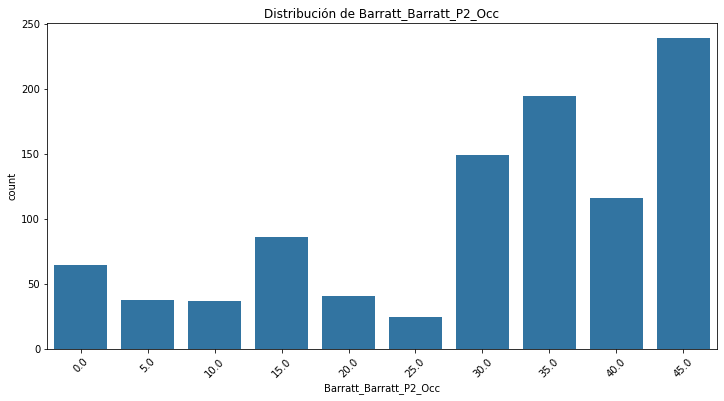

In [12]:
# Distribucion de Barratt_Barratt_P2_Occ
plt.figure(figsize=(12, 6))
sns.countplot(x='Barratt_Barratt_P2_Occ', data=train_cat[['Barratt_Barratt_P2_Occ']])
plt.title(f"Distribución de Barratt_Barratt_P2_Occ")
plt.xticks(rotation=45)
plt.show()

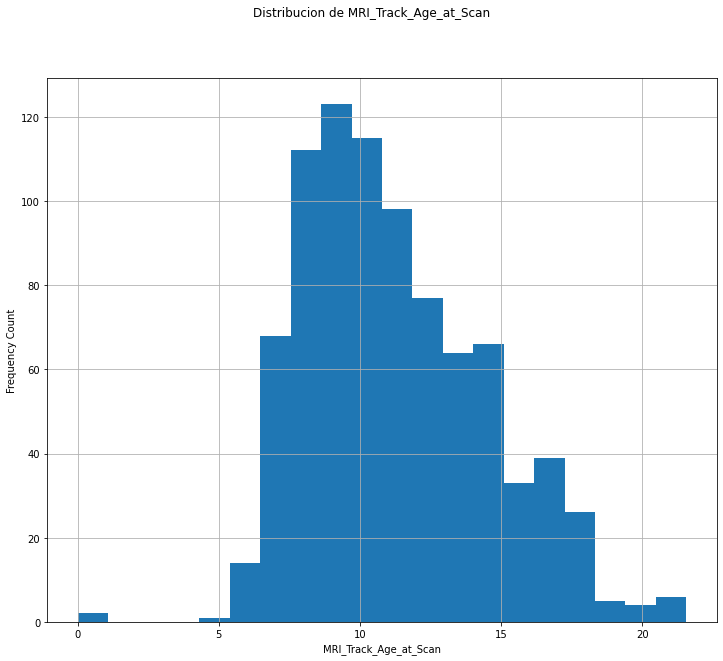

In [13]:
# Distribucion de MRI_Track_Age_at_Scan
train_quant['MRI_Track_Age_at_Scan'].hist(figsize=(12, 10), bins=20)
plt.suptitle("Distribucion de MRI_Track_Age_at_Scan")
plt.xlabel('MRI_Track_Age_at_Scan')
plt.ylabel('Frequency Count')
plt.show()

In [14]:
# Vemos la cantidad de casos psoitivos y negativos de la variable objetivo TDAH (ADHD_Outcome)
train_sol['ADHD_Outcome'].value_counts()

ADHD_Outcome
1    831
0    382
Name: count, dtype: int64

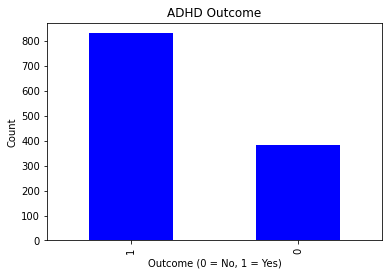

In [15]:
# Veamos la distribucion de la variable objetivo ADHD_Outcome
train_sol['ADHD_Outcome'].value_counts().plot(kind='bar', color='blue')
plt.title('ADHD Outcome')
plt.xlabel('Outcome (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

In [16]:
# La cantidad de niñas y niños en Sex_F
train_sol['Sex_F'].value_counts()

Sex_F
0    797
1    416
Name: count, dtype: int64

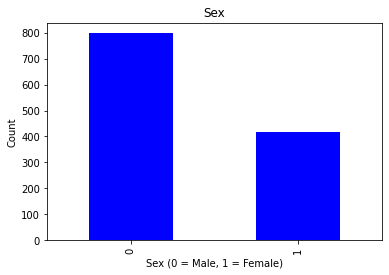

In [17]:
train_sol['Sex_F'].value_counts().plot(kind='bar', color='blue')
plt.title('Sex')
plt.xlabel('Sex (0 = Male, 1 = Female)')
plt.ylabel('Count')
plt.show()

Observamos un desvalance en la variable `Sex_F` en e conjunto de datos, debemos tenerlo en cuenta para no introduccir sesgos en el modelado.

### 3.1. <a id='toc1_3_1_'></a>[Datos cuantitativos](#toc0_)

In [18]:
train_quant.columns

Index(['participant_id', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan'],
      dtype='object')

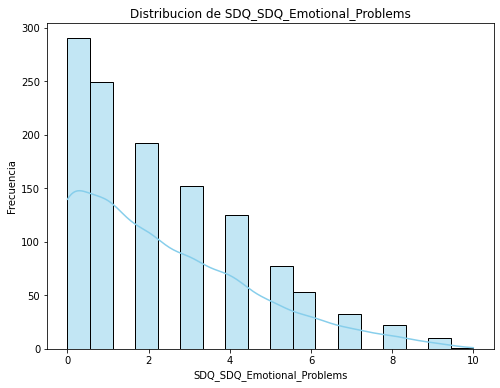

In [19]:
# Veamos SDQ_SDQ_Emotional_Problems, que indican una escala de problemas emocionales

plt.figure(figsize=(8, 6))
sns.histplot(train_quant['SDQ_SDQ_Emotional_Problems'], kde=True, color='skyblue')
plt.title('Distribucion de SDQ_SDQ_Emotional_Problems')
plt.xlabel('SDQ_SDQ_Emotional_Problems')
plt.ylabel('Frecuencia')
plt.show()

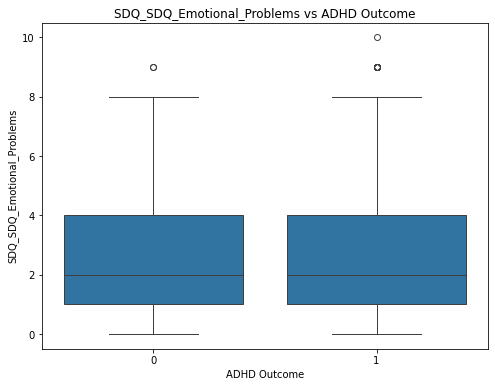

In [20]:
# Veamos la relacion entre esta variable y la variable objetivo ADHD outcome
df_train_quant = train_quant.copy()
df_train_quant['ADHD_Outcome'] = train_sol['ADHD_Outcome']

plt.figure(figsize=(8, 6))
sns.boxplot(x='ADHD_Outcome', y='SDQ_SDQ_Emotional_Problems', data=df_train_quant)
plt.title('SDQ_SDQ_Emotional_Problems vs ADHD Outcome')
plt.xlabel('ADHD Outcome')
plt.ylabel('SDQ_SDQ_Emotional_Problems')
plt.show()


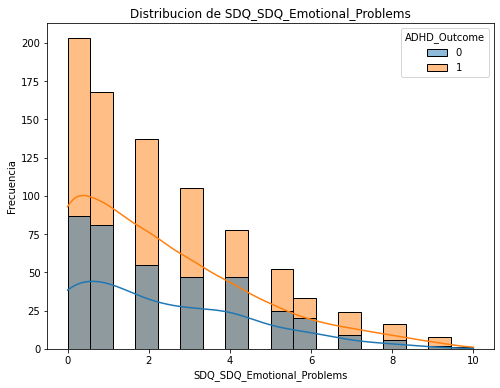

In [23]:
plt.figure(figsize=(8, 6))
sns.histplot(data=df_train_quant, x='SDQ_SDQ_Emotional_Problems', kde=True, hue="ADHD_Outcome", color='skyblue')
plt.title('Distribucion de SDQ_SDQ_Emotional_Problems')
plt.xlabel('SDQ_SDQ_Emotional_Problems')
plt.ylabel('Frecuencia')
plt.show()

In [28]:
train_quant["SDQ_SDQ_Emotional_Problems"].value_counts()

SDQ_SDQ_Emotional_Problems
0.0     290
1.0     249
2.0     192
3.0     152
4.0     125
5.0      77
6.0      53
7.0      33
8.0      22
9.0      10
10.0      1
Name: count, dtype: int64

### 1.3.2. <a id='toc1_3_2_'></a>[Datos categoricos](#toc0_)

In [24]:
train_cat.columns

Index(['participant_id', 'Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ'],
      dtype='object')

La variable `Barratt_Barratt_P1_Edu` indica el nivel educativo del primer progenitor

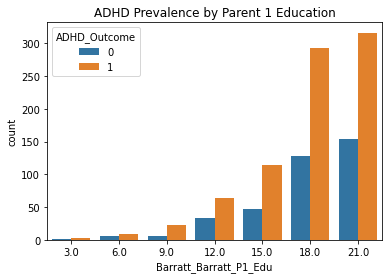

In [26]:
sns.countplot(data=train_cat, x="Barratt_Barratt_P1_Edu", hue=train_sol["ADHD_Outcome"])
plt.title('ADHD Prevalence by Parent 1 Education')
plt.show()

In [27]:
train_cat['Barratt_Barratt_P1_Edu'].value_counts()

Barratt_Barratt_P1_Edu
21.0    470
18.0    421
15.0    162
12.0     97
9.0      28
6.0      15
3.0       5
Name: count, dtype: int64